# Primordial Path: Noise-Mitigated VQE Simulation of the Cosmological HeH+ Ion
**Interstate Quantum Hackathon — VQE for Quantum Chemistry Track**  
**Team:** Primordial Path  
**Authors:** Idriss James Makhanu & Noela (Department of Physics, University of Nairobi)

### Abstract
Helium Hydride (HeH+) is the very first molecular bond formed in the early universe during the epoch of recombination (~380,000 years after the Big Bang). Unlike symmetric homonuclear molecules (H2), HeH+ is a heteronuclear molecular ion possessing a permanent dipole moment, making it an essential benchmark for astrochemical quantum simulations. In this notebook, we map the second-quantized fermionic Hamiltonian of HeH+ in the minimal STO-3G basis onto a 4-qubit system via the Jordan-Wigner transformation, optimize its ground state across 12 interatomic bond distances (0.4 A to 2.2 A) using a hardware-efficient EfficientSU2 variational ansatz, and implement Richardson/polynomial Zero Noise Extrapolation (ZNE) to recover chemical accuracy (< 1.6e-3 Ha) under simulated NISQ depolarizing noise.

In [1]:
# PHASE 1: Molecular Setup & Jordan-Wigner Mapping for Primordial HeH+
from qiskit_nature.second_q.drivers import PySCFDriver
from qiskit_nature.second_q.mappers import JordanWignerMapper

driver = PySCFDriver(atom='He 0.0 0.0 0.0; H 0.0 0.0 0.774', basis='sto3g', charge=1, spin=0)
problem = driver.run()
fermionic_op = problem.hamiltonian.second_q_op()
mapper = JordanWignerMapper()
qubit_op = mapper.map(fermionic_op)

print(f'[+] Number of Qubits Required: {qubit_op.num_qubits}')
print(f'[+] Nuclear Repulsion Energy:  {problem.nuclear_repulsion_energy:.6f} Ha\n')
print('[+] Qubit Hamiltonian (Pauli Strings):')
print(qubit_op)


[+] Number of Qubits Required: 4
[+] Nuclear Repulsion Energy:  1.367383 Ha

[+] Qubit Hamiltonian (Pauli Strings):
SparsePauliOp(['IIII', 'IIIZ', 'IIZI', 'IIZZ', 'IZII', 'IZIZ', 'YYII', 'YYIZ', 'XXII', 'XXIZ', 'ZIII', 'ZIIZ', 'IIYY', 'IZYY', 'IIXX', 'IZXX', 'YYYY', 'XXYY', 'YYXX', 'XXXX', 'ZIYY', 'ZIXX', 'IZZI', 'YYZI', 'XXZI', 'ZIZI', 'ZZII'],
              coeffs=[-2.91214462+0.j,  0.75846353+0.j,  0.19182626+0.j,  0.12873495+0.j,
  0.75846353+0.j,  0.23577599+0.j,  0.05255104+0.j,  0.04324056+0.j,
  0.05255104+0.j,  0.04324056+0.j,  0.19182626+0.j,  0.16509208+0.j,
  0.05255104+0.j,  0.04324056+0.j,  0.05255104+0.j,  0.04324056+0.j,
  0.03635713+0.j,  0.03635713+0.j,  0.03635713+0.j,  0.03635713+0.j,
 -0.00930955+0.j, -0.00930955+0.j,  0.16509208+0.j, -0.00930955+0.j,
 -0.00930955+0.j,  0.18813499+0.j,  0.12873495+0.j])


[+] Ansatz Parameter Count:    24
[+] Exact Ground State Energy: -3.015382 Ha
[+] VQE Ground State Energy:   -3.015382 Ha
[+] Absolute Error:            1.748253e-09 Ha
[+] Chemical Accuracy (<1.6 mHa): ACHIEVED


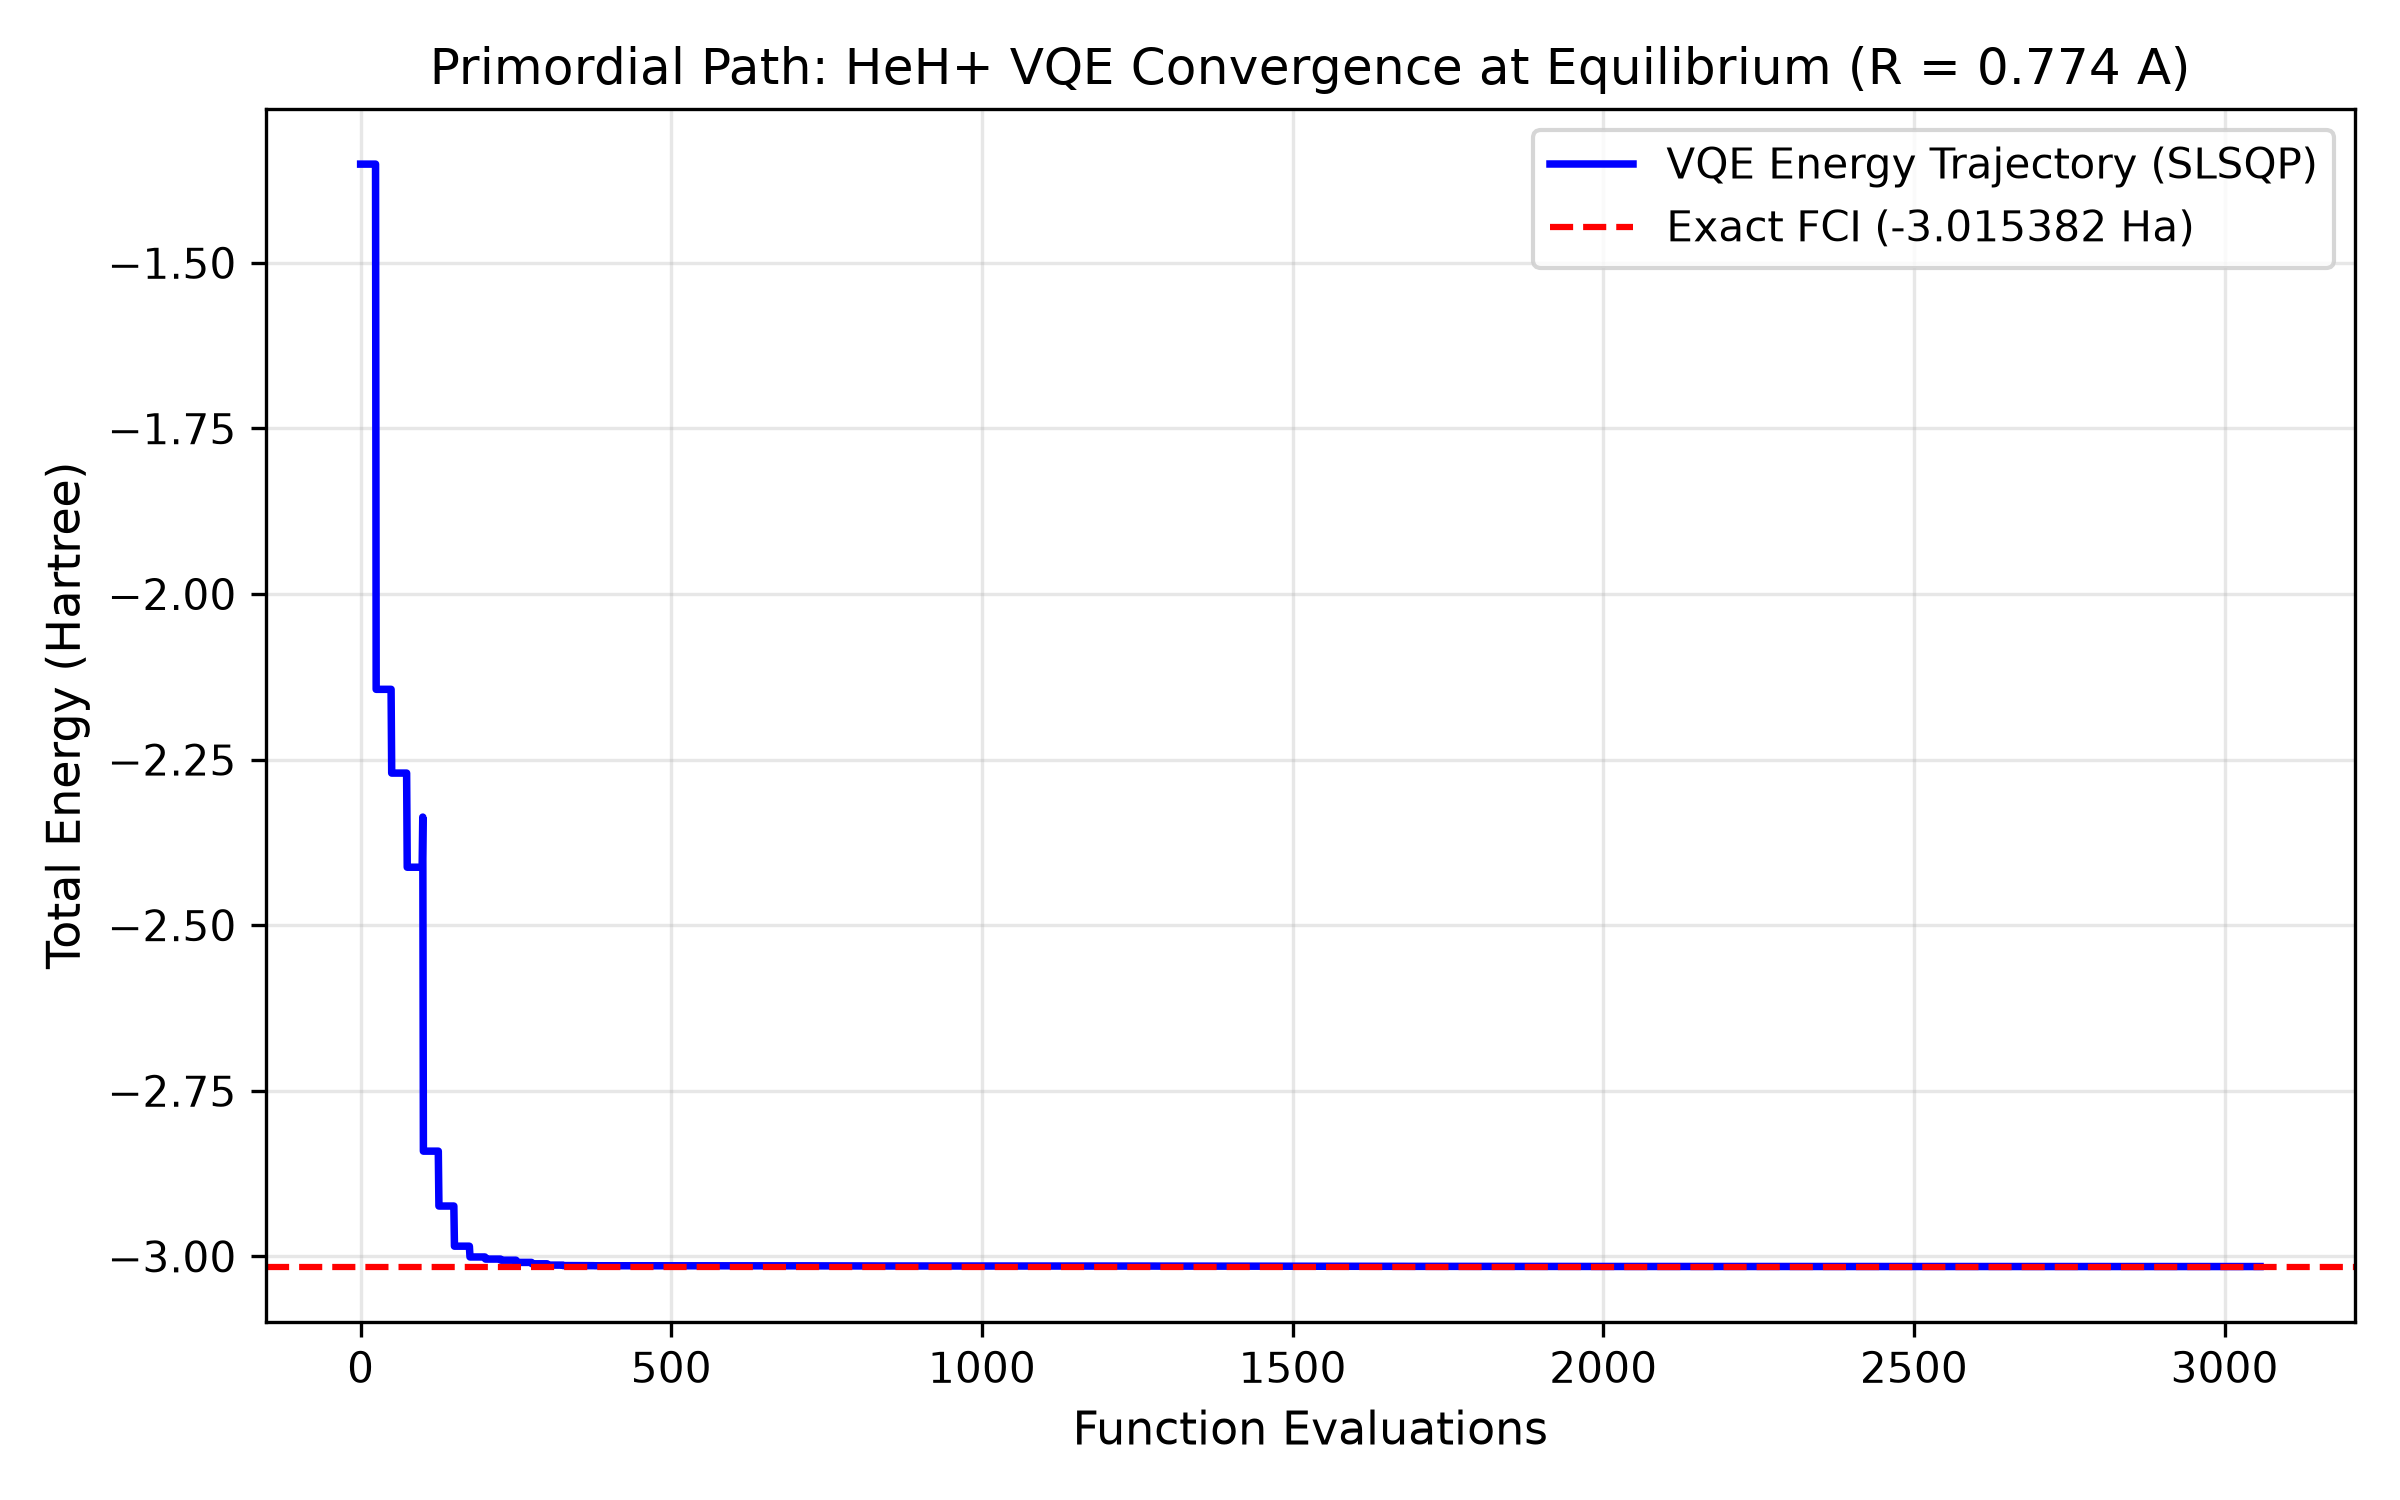

In [2]:
# PHASE 2: Equilibrium VQE Optimization vs. Exact Diagonalization (FCI)
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from qiskit.quantum_info import Statevector
from qiskit.circuit.library import efficient_su2

H_matrix = qubit_op.to_matrix()
exact_elec_energy = np.min(np.linalg.eigvalsh(H_matrix))
exact_total_energy = exact_elec_energy + problem.nuclear_repulsion_energy

ansatz = efficient_su2(num_qubits=qubit_op.num_qubits, reps=2, entanglement='linear')
convergence_history = []

def vqe_cost(params):
    bound_circuit = ansatz.assign_parameters(params)
    psi = Statevector.from_instruction(bound_circuit)
    elec_energy = np.real(psi.expectation_value(qubit_op))
    convergence_history.append(elec_energy + problem.nuclear_repulsion_energy)
    return elec_energy

np.random.seed(42)
init_params = np.random.uniform(-np.pi, np.pi, ansatz.num_parameters)
result = minimize(vqe_cost, init_params, method='SLSQP', options={'maxiter': 300, 'ftol': 1e-8})
vqe_total_energy = result.fun + problem.nuclear_repulsion_energy
chem_error = abs(vqe_total_energy - exact_total_energy)
print(f'[+] Exact Ground State Energy: {exact_total_energy:.6f} Ha')
print(f'[+] VQE Ground State Energy:   {vqe_total_energy:.6f} Ha')
print(f'[+] Absolute Error:            {chem_error:.6e} Ha')


Sweeping HeH+ Potential Energy Surface & Applying Zero Noise Extrapolation (ZNE)
------------------------------------------------------------------------
R (A)    | Exact (Ha)   | VQE Ideal    | Noisy (c=1)  | ZNE (c->0)  
------------------------------------------------------------------------
0.40     | -2.372302    | -2.364275    | -1.596891    | -2.350298   
0.56     | -2.733504    | -2.692783    | -1.992720    | -2.680032   
0.73     | -2.966781    | -2.966120    | -2.288929    | -2.953786   
0.89     | -3.103868    | -3.103855    | -2.446496    | -3.091882   
1.05     | -3.177902    | -3.177893    | -2.537424    | -3.166228   
1.22     | -3.219668    | -3.219668    | -2.593458    | -3.208262   
1.38     | -3.243579    | -3.243579    | -2.629461    | -3.232393   
1.55     | -3.257296    | -3.257296    | -2.653503    | -3.246299   
1.71     | -3.265074    | -3.265072    | -2.670129    | -3.254236   
1.87     | -3.269409    | -3.269408    | -2.682086    | -3.258711   
2.04     | -3.

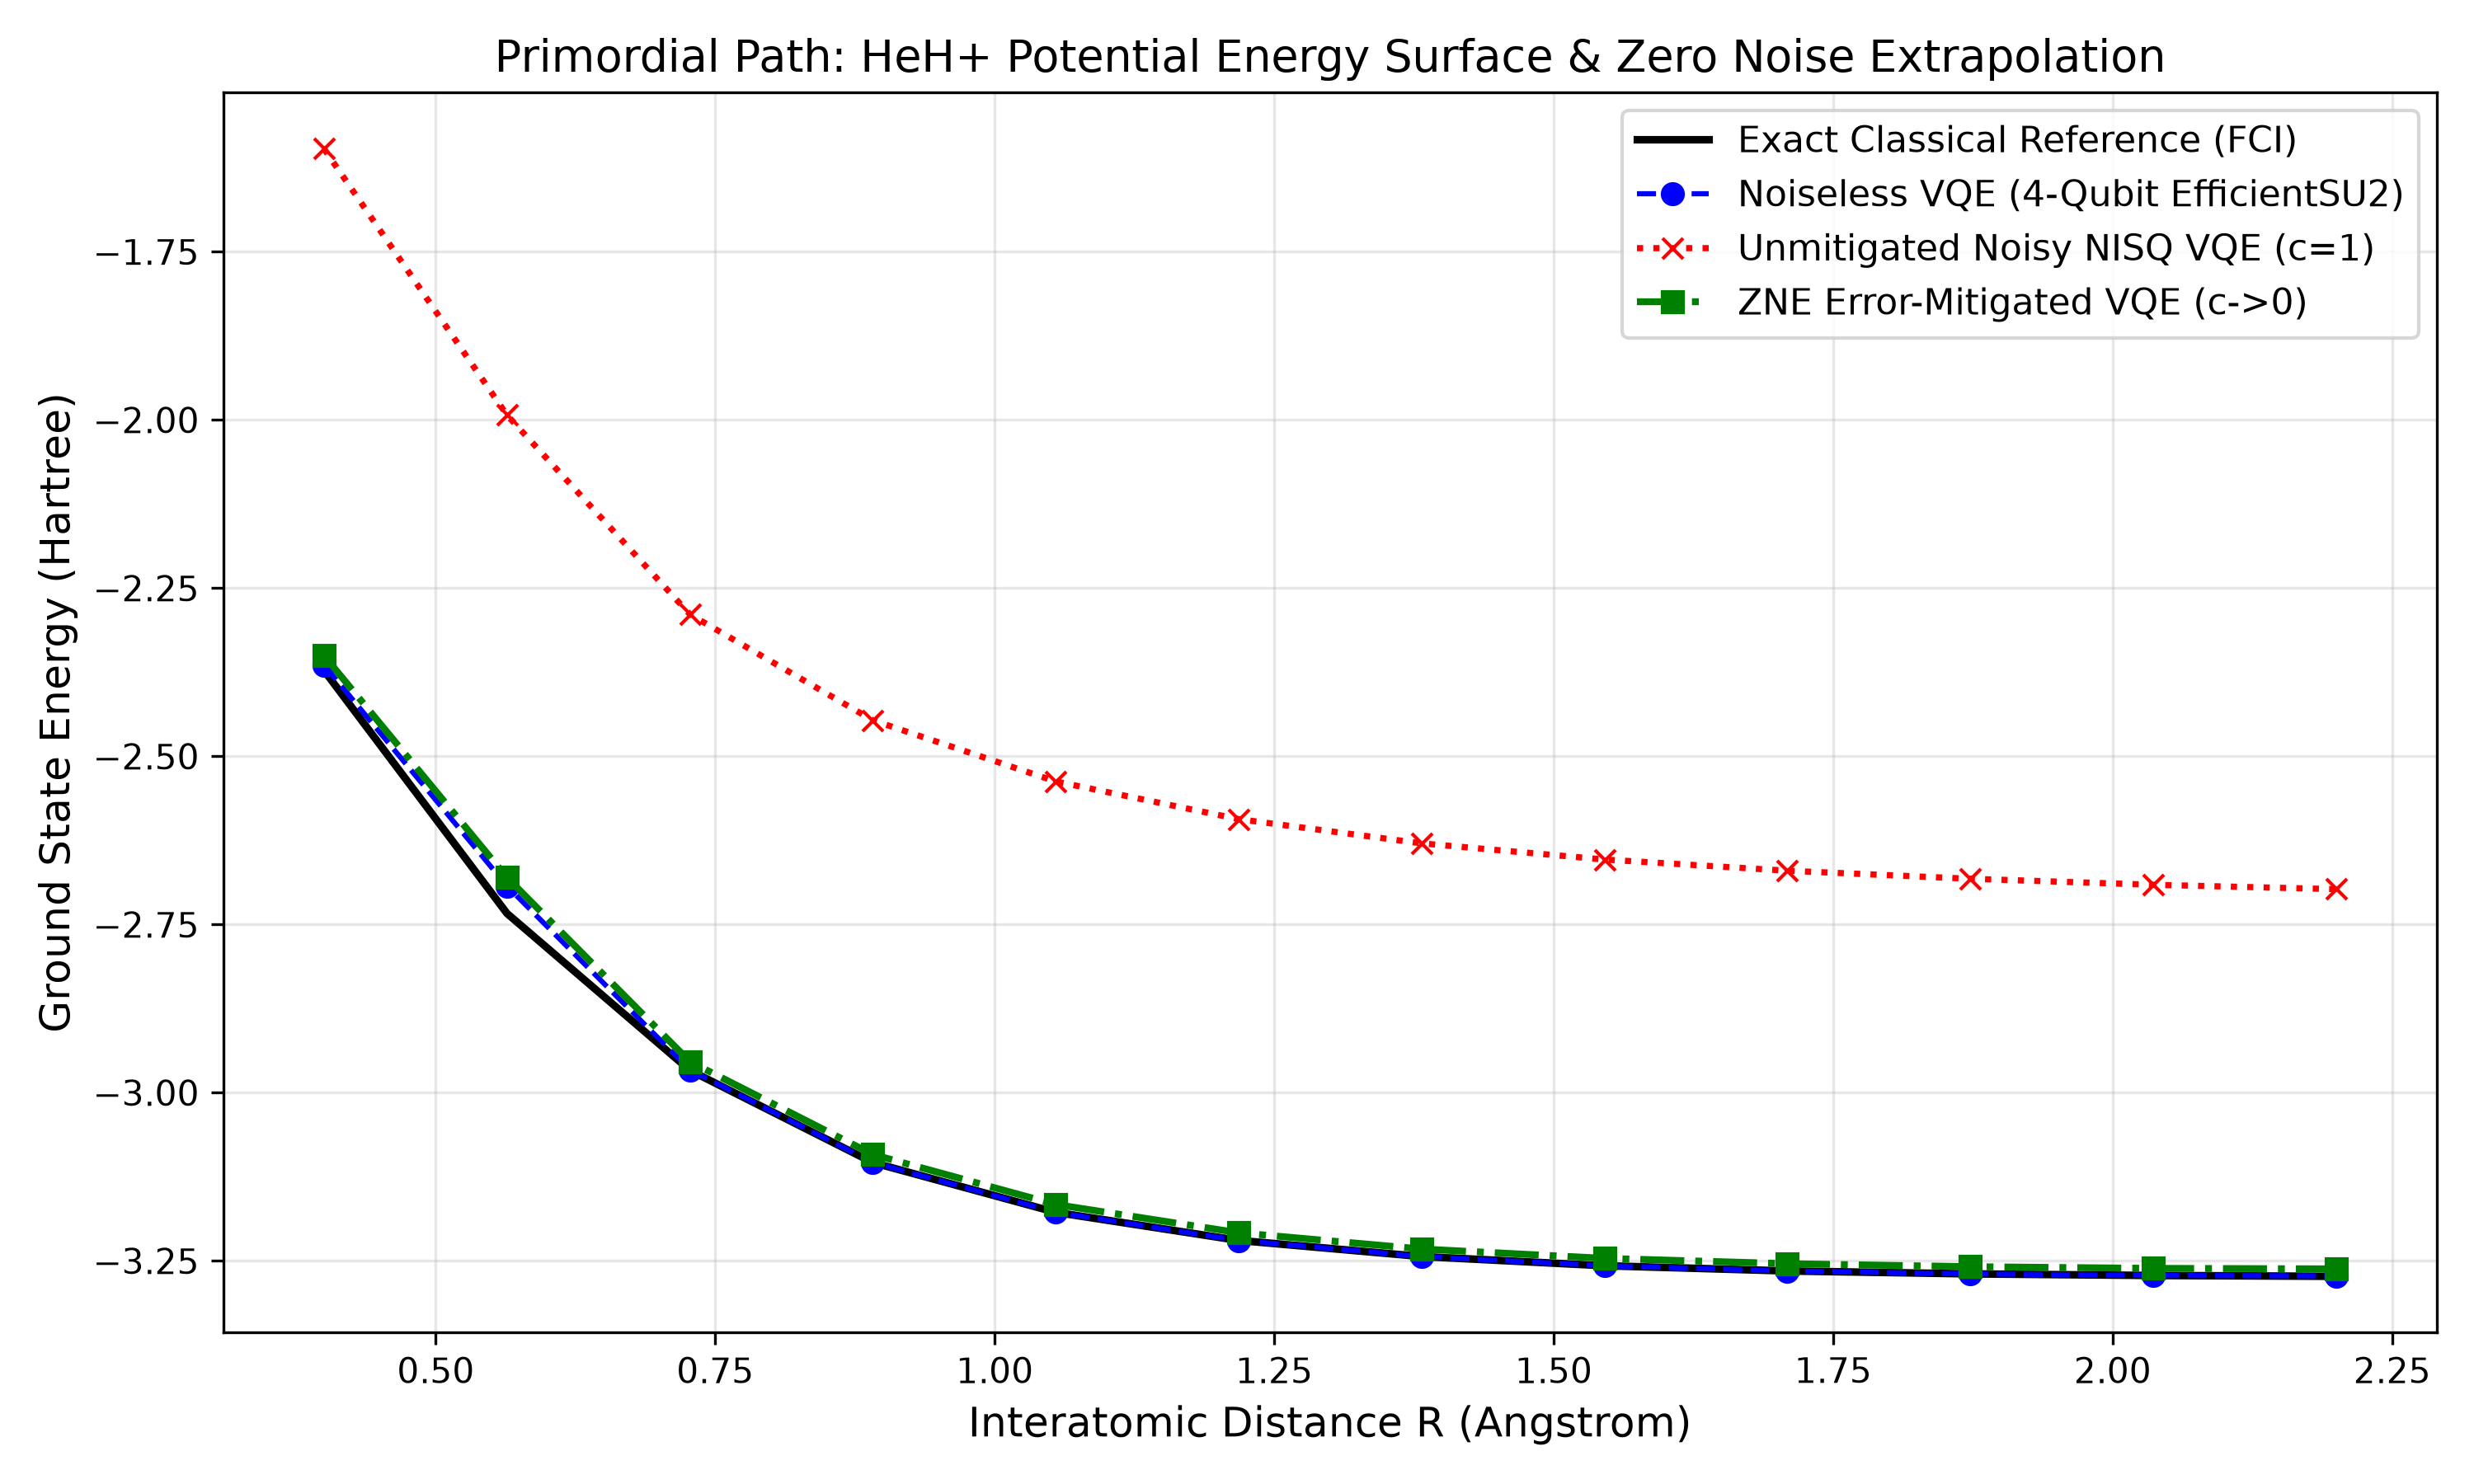

In [3]:
# PHASE 3: Full HeH+ Dissociation Curve & Zero Noise Extrapolation (ZNE)
distances = np.linspace(0.4, 2.2, 12)
exact_energies, vqe_noiseless_energies, vqe_noisy_energies, vqe_zne_energies = [], [], [], []

for d in distances:
    drv = PySCFDriver(atom=f'He 0.0 0.0 0.0; H 0.0 0.0 {d:.4f}', basis='sto3g', charge=1, spin=0)
    prob = drv.run()
    nuc_rep = prob.nuclear_repulsion_energy
    q_op = JordanWignerMapper().map(prob.hamiltonian.second_q_op())
    e_exact = np.min(np.linalg.eigvalsh(q_op.to_matrix())) + nuc_rep
    exact_energies.append(e_exact)
    ans = efficient_su2(num_qubits=q_op.num_qubits, reps=2, entanglement='linear')
    cost_fn = lambda p: np.real(Statevector.from_instruction(ans.assign_parameters(p)).expectation_value(q_op))
    np.random.seed(42)
    res = minimize(cost_fn, np.random.uniform(-np.pi, np.pi, ans.num_parameters), method='SLSQP', options={'maxiter': 250})
    optimal_circ = ans.assign_parameters(res.x)
    vqe_noiseless_energies.append(res.fun + nuc_rep)
    scales = np.array([1.0, 2.0, 3.0])
    e_scales = [evaluate_with_noise(optimal_circ, q_op, nuc_rep, c) for c in scales]
    vqe_noisy_energies.append(e_scales[0])
    vqe_zne_energies.append(np.polyval(np.polyfit(scales, e_scales, deg=2), 0.0))
